# Perceptron for Boolean Functions

Implement a single-layer perceptron from scratch and investigate which Boolean functions a linear decision boundary can represent.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

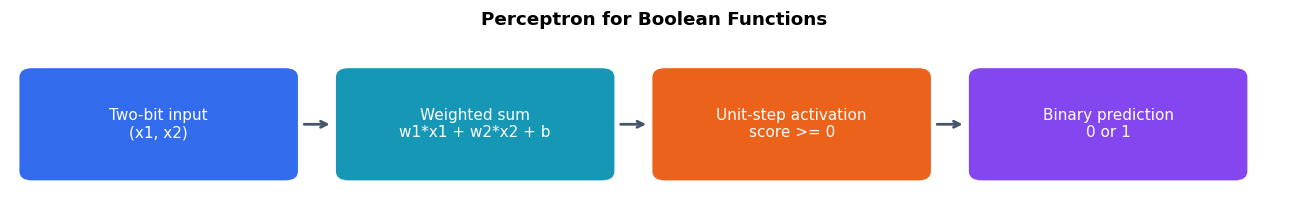

In [2]:
show_architecture(['Two-bit input\n(x1, x2)', 'Weighted sum\nw1*x1 + w2*x2 + b', 'Unit-step activation\nscore >= 0', 'Binary prediction\n0 or 1'], 'Perceptron for Boolean Functions')

In [3]:
import numpy as np
import matplotlib.pyplot as plt

## Implement the perceptron

In [4]:
class Perceptron:
    """Binary linear classifier trained with the perceptron update rule."""

    def __init__(self, input_size, learning_rate=0.1, epochs=100):
        if input_size < 1 or learning_rate <= 0 or epochs < 1:
            raise ValueError("Input size, learning rate, and epochs must be positive.")
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = np.zeros(input_size, dtype=float)
        self.bias = 0.0
        self.errors = []
        self.converged = False

    def activation(self, z):
        return np.asarray(z >= 0, dtype=int)

    def predict(self, X):
        return self.activation(np.asarray(X) @ self.weights + self.bias)

    def fit(self, X, y, verbose=True):
        """Fit from zero initialization; log online mistakes at each epoch."""
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        if X.ndim != 2 or X.shape[1] != len(self.weights):
            raise ValueError("X must have shape (samples, input_size).")
        if y.shape != (len(X),) or not len(X) or not np.isin(y, [0, 1]).all():
            raise ValueError("y must contain one binary label per sample.")
        self.weights.fill(0)
        self.bias = 0.0
        self.errors = []
        self.converged = False
        for epoch in range(self.epochs):
            mistakes = 0
            for xi, target in zip(X, y):
                error = int(target - self.predict(xi))
                self.weights += self.lr * error * xi
                self.bias += self.lr * error
                mistakes += abs(error)
            self.errors.append(mistakes)
            if verbose:
                print(f"Epoch {epoch + 1:3d}: online mistakes = {mistakes}")
            if mistakes == 0:
                self.converged = True
                break
        self.n_epochs = len(self.errors)
        return self.n_epochs

## Boolean truth tables

In [5]:
# TRUTH TABLES

X = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
])

AND = np.array([0,0,0,1])

OR = np.array([0,1,1,1])

NAND = np.array([1,1,1,0])

NOR = np.array([1,0,0,0])

XOR = np.array([0,1,1,0])

### Truth-table overview

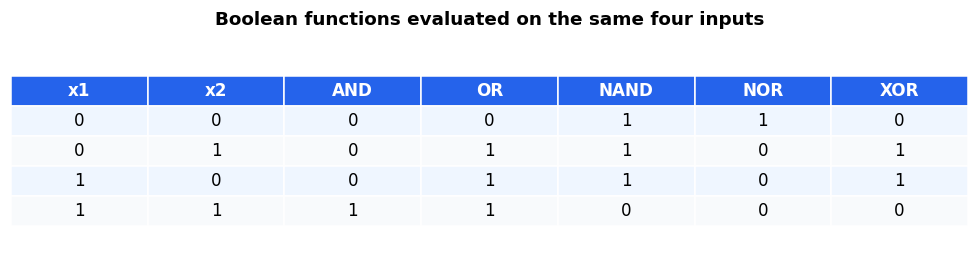

In [6]:
truth_rows = np.column_stack([X, AND, OR, NAND, NOR, XOR]).astype(int)
fig, ax = plt.subplots(figsize=(9, 2.5)); ax.axis('off')
table = ax.table(cellText=truth_rows, colLabels=['x1', 'x2', 'AND', 'OR', 'NAND', 'NOR', 'XOR'],
                 cellLoc='center', loc='center')
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1, 1.7)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('white')
    cell.set_facecolor('#2563eb' if row==0 else '#eff6ff' if row%2 else '#f8fafc')
    if row==0: cell.set_text_props(color='white',weight='bold')
ax.set_title('Boolean functions evaluated on the same four inputs',pad=16)
plt.tight_layout(); plt.show()

## Train and inspect predictions

In [7]:
# FUNCTION TO TRAIN AND DISPLAYING RESULTS

def train_gate(name, X, y):

    print("="*50)
    print(name)
    print("="*50)

    p = Perceptron(input_size=2,
                   learning_rate=0.1,
                   epochs=100)

    epochs = p.fit(X, y)

    predictions = p.predict(X)

    print("\nFinal Weights")
    print("w1 =", p.weights[0])
    print("w2 =", p.weights[1])
    print("Bias =", p.bias)
    print("Epochs =", epochs)

    print("\nPrediction Table")

    print("--------------------------------------")
    print("x1 x2 | Target | Output")
    print("--------------------------------------")

    for inp, target, pred in zip(X, y, predictions):
        print(f"{inp}   {target}        {pred}")

    return p

In [8]:
# TRAIN AND

and_model = train_gate("AND Gate", X, AND)

AND Gate
Epoch   1: online mistakes = 2
Epoch   2: online mistakes = 3
Epoch   3: online mistakes = 3
Epoch   4: online mistakes = 0

Final Weights
w1 = 0.2
w2 = 0.1
Bias = -0.20000000000000004
Epochs = 4

Prediction Table
--------------------------------------
x1 x2 | Target | Output
--------------------------------------
[0 0]   0        0
[0 1]   0        0
[1 0]   0        0
[1 1]   1        1


In [9]:
# TRAIN OR

or_model = train_gate("OR Gate", X, OR)

OR Gate
Epoch   1: online mistakes = 2
Epoch   2: online mistakes = 2
Epoch   3: online mistakes = 1
Epoch   4: online mistakes = 0

Final Weights
w1 = 0.1
w2 = 0.1
Bias = -0.1
Epochs = 4

Prediction Table
--------------------------------------
x1 x2 | Target | Output
--------------------------------------
[0 0]   0        0
[0 1]   1        1
[1 0]   1        1
[1 1]   1        1


In [10]:
# TRAIN NAND

nand_model = train_gate("NAND Gate", X, NAND)

NAND Gate
Epoch   1: online mistakes = 1
Epoch   2: online mistakes = 3
Epoch   3: online mistakes = 3
Epoch   4: online mistakes = 2
Epoch   5: online mistakes = 1
Epoch   6: online mistakes = 0

Final Weights
w1 = -0.2
w2 = -0.1
Bias = 0.2
Epochs = 6

Prediction Table
--------------------------------------
x1 x2 | Target | Output
--------------------------------------
[0 0]   1        1
[0 1]   1        1
[1 0]   1        1
[1 1]   0        0


In [11]:
# TRAIN NOR

nor_model = train_gate("NOR Gate", X, NOR)

NOR Gate
Epoch   1: online mistakes = 1
Epoch   2: online mistakes = 2
Epoch   3: online mistakes = 1
Epoch   4: online mistakes = 0

Final Weights
w1 = -0.1
w2 = -0.1
Bias = 0.0
Epochs = 4

Prediction Table
--------------------------------------
x1 x2 | Target | Output
--------------------------------------
[0 0]   1        1
[0 1]   0        0
[1 0]   0        0
[1 1]   0        0


In [12]:
# TRAIN XOR

xor_model = train_gate("XOR Gate", X, XOR)

XOR Gate
Epoch   1: online mistakes = 3
Epoch   2: online mistakes = 3
Epoch   3: online mistakes = 4
Epoch   4: online mistakes = 4
Epoch   5: online mistakes = 4
Epoch   6: online mistakes = 4
Epoch   7: online mistakes = 4
Epoch   8: online mistakes = 4
Epoch   9: online mistakes = 4
Epoch  10: online mistakes = 4
Epoch  11: online mistakes = 4
Epoch  12: online mistakes = 4
Epoch  13: online mistakes = 4
Epoch  14: online mistakes = 4
Epoch  15: online mistakes = 4
Epoch  16: online mistakes = 4
Epoch  17: online mistakes = 4
Epoch  18: online mistakes = 4
Epoch  19: online mistakes = 4
Epoch  20: online mistakes = 4
Epoch  21: online mistakes = 4
Epoch  22: online mistakes = 4
Epoch  23: online mistakes = 4
Epoch  24: online mistakes = 4
Epoch  25: online mistakes = 4
Epoch  26: online mistakes = 4
Epoch  27: online mistakes = 4
Epoch  28: online mistakes = 4
Epoch  29: online mistakes = 4
Epoch  30: online mistakes = 4
Epoch  31: online mistakes = 4
Epoch  32: online mistakes = 4

## Learning curves

In [13]:
# ERROR PLOT

def plot_error(model, title):

    plt.figure(figsize=(6,4))
    plt.plot(range(1, len(model.errors)+1),
             model.errors,
             marker='o')

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Online mistakes per epoch")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

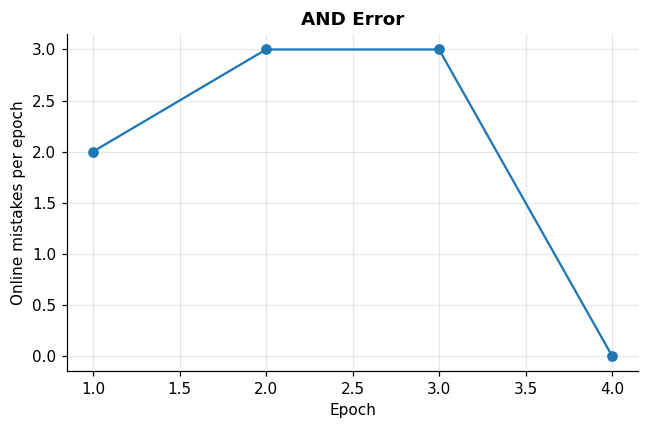

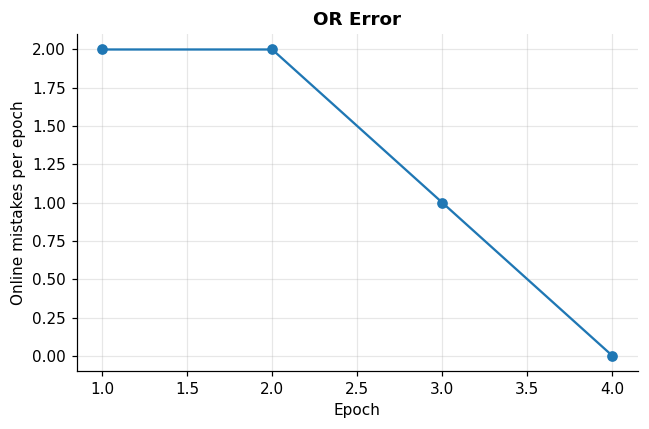

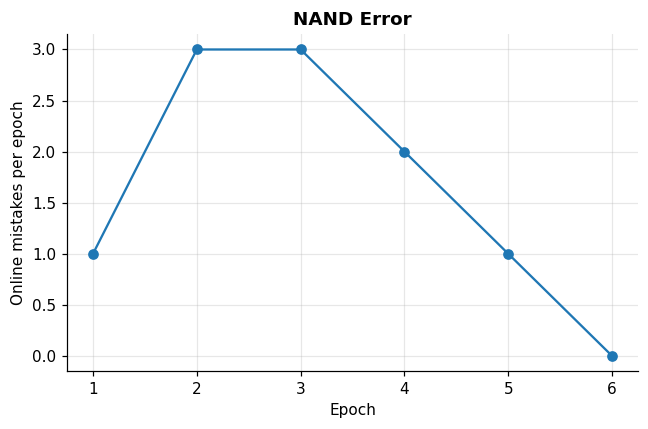

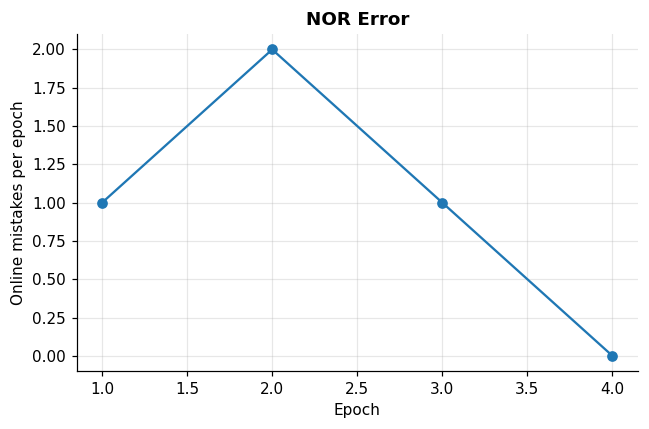

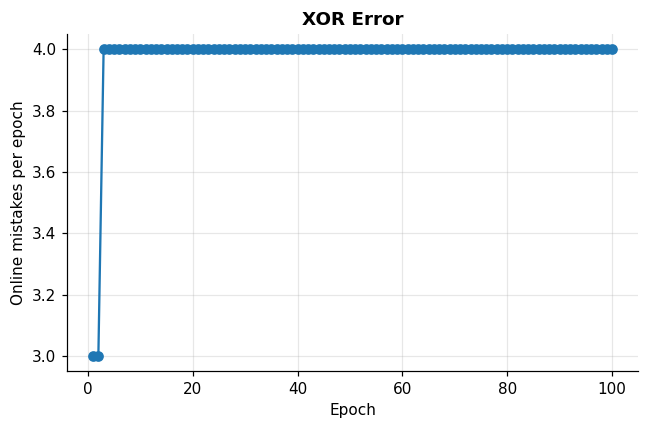

In [14]:
plot_error(and_model,"AND Error")
plot_error(or_model,"OR Error")
plot_error(nand_model,"NAND Error")
plot_error(nor_model,"NOR Error")
plot_error(xor_model,"XOR Error")

## Decision boundaries

The XOR plot shows the final attempted linear boundary; it does not imply successful separation.

In [15]:
# DECISION BOUNDARY

def plot_boundary(model, X, y, title):

    plt.figure(figsize=(5,5))

    for point, label in zip(X, y):

        if label == 0:
            plt.scatter(point[0], point[1],
                        color='red',
                        s=100)

        else:
            plt.scatter(point[0], point[1],
                        color='blue',
                        s=100)

        plt.text(point[0]+0.02,
                 point[1]+0.02,
                 str(label))

    x = np.linspace(-0.5,1.5,100)

    if not np.isclose(model.weights[1], 0):

        y_line = -(model.weights[0]*x + model.bias)/model.weights[1]

        plt.plot(x, y_line, color="black", label="Decision boundary")
    elif not np.isclose(model.weights[0], 0):
        plt.axvline(-model.bias / model.weights[0], color="black", label="Decision boundary")
    else:
        plt.text(0.5, 1.3, "No unique boundary: zero weights", ha="center")

    plt.xlim(-0.5,1.5)
    plt.ylim(-0.5,1.5)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.grid(alpha=0.3)
    if not np.allclose(model.weights, 0):
        plt.legend()
    plt.tight_layout()

    plt.show()

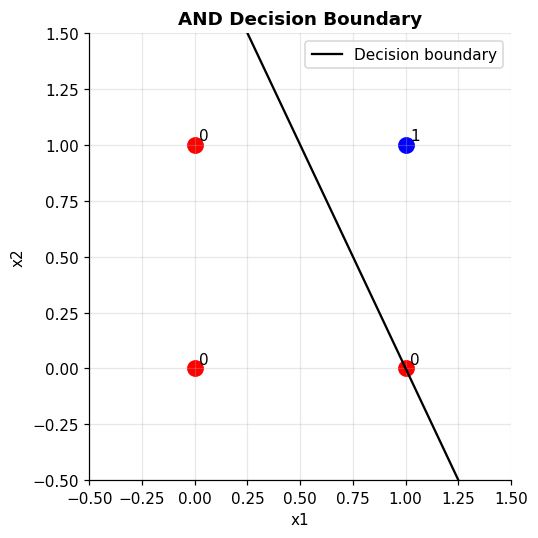

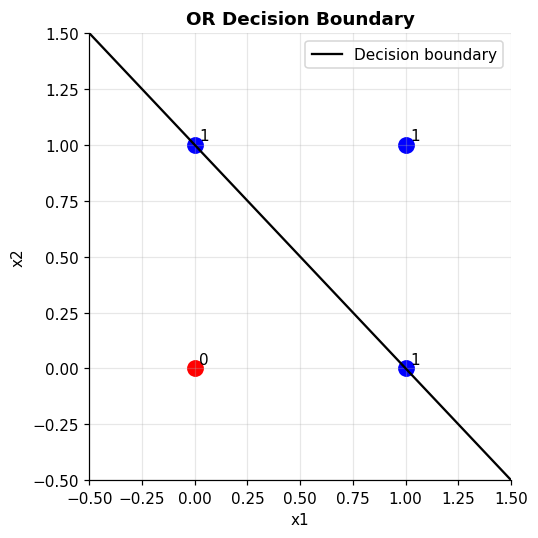

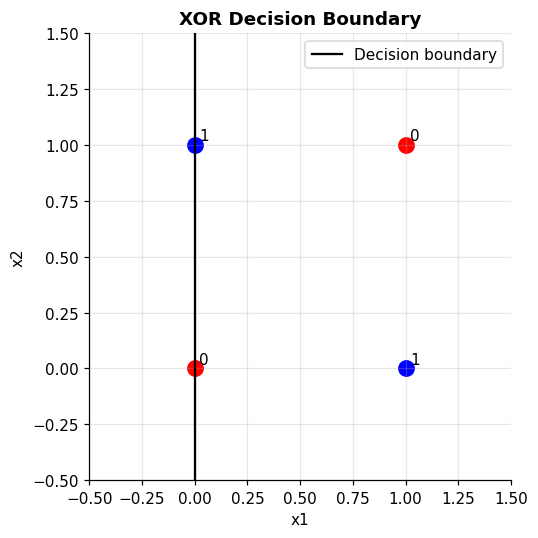

In [16]:
plot_boundary(and_model,X,AND,"AND Decision Boundary")
plot_boundary(or_model,X,OR,"OR Decision Boundary")
plot_boundary(xor_model,X,XOR,"XOR Decision Boundary")

## Results

In [17]:
models = {"AND": and_model, "OR": or_model, "NAND": nand_model,
          "NOR": nor_model, "XOR": xor_model}
targets = {"AND": AND, "OR": OR, "NAND": NAND, "NOR": NOR, "XOR": XOR}
print(f"{'Gate':<6} {'w1':>8} {'w2':>8} {'Bias':>8} {'Epochs':>8} {'Converged':>11} {'Final mistakes':>15}")
for name, model in models.items():
    final_mistakes = np.count_nonzero(model.predict(X) != targets[name])
    print(f"{name:<6} {model.weights[0]:8.3f} {model.weights[1]:8.3f} "
          f"{model.bias:8.3f} {model.n_epochs:8d} {str(model.converged):>11} {final_mistakes:15d}")

Gate         w1       w2     Bias   Epochs   Converged  Final mistakes
AND       0.200    0.100   -0.200        4        True               0
OR        0.100    0.100   -0.100        4        True               0
NAND     -0.200   -0.100    0.200        6        True               0
NOR      -0.100   -0.100    0.000        4        True               0
XOR      -0.100    0.000    0.000      100       False               2


### Why XOR cannot converge

A separating classifier must label $(0,0)$ and $(1,1)$ as zero, requiring $b<0$ and $w_1+w_2+b<0$. It must label $(1,0)$ and $(0,1)$ as one, requiring $w_1+b\geq0$ and $w_2+b\geq0$. Adding these gives $w_1+w_2+2b\geq0$, hence $w_1+w_2+b\geq-b>0$: a contradiction. XOR is not linearly separable, so more epochs cannot solve it with this architecture.

## Learning-rate experiment

Compare 0.01, 0.1, and 0.5 with the same initialization and sample order.

In [18]:
print(f"{'Gate':<6} {'Rate':>8} {'Epochs':>8} {'Converged':>11}")
for name, target in targets.items():
    for rate in [0.01, 0.1, 0.5]:
        trial = Perceptron(input_size=2, learning_rate=rate, epochs=100)
        trial.fit(X, target, verbose=False)
        print(f"{name:<6} {rate:8.2f} {trial.n_epochs:8d} {str(trial.converged):>11}")

Gate       Rate   Epochs   Converged
AND        0.01        6        True
AND        0.10        4        True
AND        0.50        6        True
OR         0.01        4        True
OR         0.10        4        True
OR         0.50        4        True
NAND       0.01        6        True
NAND       0.10        6        True
NAND       0.50        6        True
NOR        0.01        4        True
NOR        0.10        4        True
NOR        0.50        4        True
XOR        0.01      100       False
XOR        0.10      100       False
XOR        0.50      100       False


### Interpretation

For this zero-initialized perceptron, changing a fixed positive learning rate scales every weight and bias update. In exact arithmetic, the sign of the score, the mistake sequence, and the convergence epoch therefore remain unchanged. Floating-point rounding near a score of zero can introduce small differences; use the executed table to check the outcome.

The usual statement that a smaller learning rate necessarily slows training does not follow for this setup. A perceptron uses discrete mistake-driven updates, rather than gradient descent on a smooth loss. AND, OR, NAND, and NOR are representable by a line; XOR requires a nonlinear representation, such as an MLP with a hidden layer.